In [6]:
#Project 1: Handwritten Digit Recognition using Neural Networks

In [7]:
pip install tensorflow numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9232 - loss: 0.2578 - val_accuracy: 0.9650 - val_loss: 0.1132
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9674 - loss: 0.1050 - val_accuracy: 0.9730 - val_loss: 0.0899
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9777 - loss: 0.0714 - val_accuracy: 0.9775 - val_loss: 0.0820
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9821 - loss: 0.0552 - val_accuracy: 0.9795 - val_loss: 0.0792
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9868 - loss: 0.0407 - val_accuracy: 0.9772 - val_loss: 0.0862
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9758 - loss: 0.0817
Test Accuracy: 97.57999777793884 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
Predicted: 7 Actual: 7
Predicted: 2 Actual: 2
Predicted: 1 Actual: 1
Predicted: 0 Actual: 0
Predicted: 4 Actual: 4


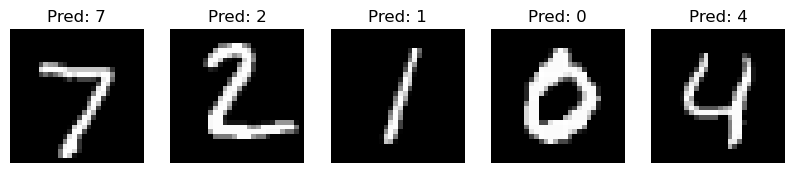

Model saved successfully!


In [8]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load MNIST dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

# Step 2: Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# Step 3: Build Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 4: Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 5: Train model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

# Step 6: Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")

# Step 7: Predict digit
predictions = model.predict(x_test[:5])

for i in range(5):
    print("Predicted:", np.argmax(predictions[i]),
          "Actual:", y_test[i])

# Step 8: Display sample prediction
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Pred: {np.argmax(predictions[i])}")
    plt.axis('off')

plt.show()

# Step 9: Save model
model.save("digit_model.keras")
print("Model saved successfully!")
